# DataHub — Galaxy Star Formation Rate Prediction
## Midterm + Final Scientific Report Template

This notebook is both your **analysis code** and your **scientific report**. Use the **same notebook for both submission stages**.

- **Part I — Midterm Report:** complete all required Part I sections and submit the notebook.
- **Part II — Final Report:** continue in the same notebook, preserve Part I, and complete the final analysis, code, results, and discussion.

## Participant Information

**Application ID**

**email:**

---
# Part I — Midterm Report

**Goal:** establish a scientifically motivated modeling plan. Part I should demonstrate that you understand the prediction problem, have inspected the data carefully, established a defensible validation procedure, and produced preliminary results.

### Part I deliverables
1. Problem & objective
2. Data loading and quality checks
3. Exploratory data analysis
4. Data preparation and feature engineering
5. Validation and evaluation strategy
6. Baseline results
7. Preliminary model / proposed method
8. Midterm summary and next-step plan

## 1. Problem & Objective — **STUDENT RESPONSE**

In approximately **150–250 words**, explain:
- what quantity you are predicting;
- what information is available as input;
- why this is a non-trivial regression problem;
- one or more astrophysical considerations that may affect the prediction.

**Response:**  
...

## 2. Setup, Reproducibility & Data Loading

The fixed cells below establish common imports, a random seed, and basic schema checks. You may change the data path if necessary, but do not silently alter the raw data.

In [1]:
# DO NOT MODIFY — core imports and seed
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
pd.set_option("display.max_columns", 100)
print("Random seed:", RANDOM_SEED)

Random seed: 42


In [4]:
# You may change DATA_PATH only if needed.
CANDIDATES = [
    Path("Galaxy Features with Position and Velocity for Star Formation Rate Prediction.csv"),
    Path("/mnt/data/Galaxy Features with Position and Velocity for Star Formation Rate Prediction.csv"),
]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found. Place the course CSV beside this notebook or update DATA_PATH.")

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Shape: (208437, 15)


,subhalo_id,log10_halo_mass,log10_stellar_mass,log10_BH_mass,log10_main_prog_mass,log10_main_prog_stellar_mass,log10_mass_ratio,log10_overdensity_plus_1,pos_x,pos_y,pos_z,vel_x,vel_y,vel_z,sfr_linear
0,0.0,14.807566,12.812004,10.443699,14.631294,12.589542,-3.239739,2.383863,21.290455,101.703239,118.123352,-287.557892,-62.394615,-30.580877,107.896912
1,1.0,13.870680,12.091579,8.625058,13.819390,11.916792,-6.000000,2.025288,20.735514,101.805397,120.937294,786.127563,258.246796,-680.667908,68.733315
2,2.0,13.672584,12.032370,9.829654,13.620131,11.864630,-6.000000,1.704644,18.711687,103.225121,120.417160,890.943054,-756.617004,-358.727631,0.232002
3,3.0,13.650022,12.019966,9.312719,13.577394,11.849984,-6.000000,1.833376,23.493862,102.198166,113.814438,-92.127396,532.597473,544.153687,12.698732
4,4.0,13.131606,11.563723,9.452775,13.026983,11.395634,-6.000000,1.830341,24.067015,101.780312,112.495789,-187.708572,-224.876968,978.109558,0.715540


In [5]:
# DO NOT MODIFY — schema checks
TARGET = "sfr_linear"
ID_COLUMN = "subhalo_id"
EXPECTED_COLUMNS = [
    "subhalo_id", "log10_halo_mass", "log10_stellar_mass", "log10_BH_mass",
    "log10_main_prog_mass", "log10_main_prog_stellar_mass", "log10_mass_ratio",
    "log10_overdensity_plus_1", "pos_x", "pos_y", "pos_z",
    "vel_x", "vel_y", "vel_z", "sfr_linear"
]
missing = sorted(set(EXPECTED_COLUMNS) - set(df.columns))
if missing:
    raise ValueError(f"Missing expected columns: {missing}")
n_missing_target = int(df[TARGET].isna().sum())
print(f"Missing target values: {n_missing_target}")
if n_missing_target > 0:
    print(f"Dropping {n_missing_target} row(s) with missing target before modeling.")
    df = df.dropna(subset=[TARGET]).copy()
print(f"Schema check passed. Samples available for modeling: {len(df):,}")


Missing target values: 0
Schema check passed. Samples available for modeling: 208,437


### 2.1 Data Quality Notes — **STUDENT RESPONSE**

Report the dataset size, missing values, duplicate handling (if any), and any other data-quality issue you found. Remember that **`sfr_linear = 0` is a valid physical target and is not the same as a missing value**.

**Response:**  
...

## 3. Exploratory Data Analysis (EDA) — **STUDENT WORK**

Your EDA should be selective and scientifically useful rather than a gallery of plots. Include **at least two analyses/figures that influence a later modeling decision**. At minimum, examine the target distribution and relevant relationships between predictors and SFR.

For every important figure/table, add a short interpretation directly below it: **What does it show? Why might the pattern occur? How does it affect your modeling choices?**

In [6]:
# STUDENT TODO — starter summary
print(df[TARGET].describe(percentiles=[0.5, 0.9, 0.99]))
zero_fraction = (df[TARGET] == 0).mean()
print(f"Exact zero-SFR fraction: {zero_fraction:.2%}")

# Add your EDA here.

count    208437.000000
mean          3.709985
std          11.794583
min           0.000000
50%           1.631928
90%           7.554342
99%          34.859419
max        2145.372800
Name: sfr_linear, dtype: float64
Exact zero-SFR fraction: 8.66%


### 3.1 EDA Findings — **STUDENT RESPONSE**

**Finding 1:** ...  
**Finding 2:** ...  
**Additional finding(s):** ...  

**Modeling decisions motivated by the EDA:** ...

## 4. Data Preparation & Feature Engineering — **STUDENT WORK**

Document all choices that affect model inputs. Discuss feature inclusion/exclusion, missing-value treatment, transformations, scaling, and engineered features where applicable. **`subhalo_id` must not be used as a predictive feature.**

In [7]:
# Default allowed feature set. You may modify FINAL_FEATURES, but never include subhalo_id or sfr_linear.
ALLOWED_FEATURES = [c for c in df.columns if c not in [ID_COLUMN, TARGET]]
FINAL_FEATURES = ALLOWED_FEATURES.copy()

assert ID_COLUMN not in FINAL_FEATURES
assert TARGET not in FINAL_FEATURES
assert set(FINAL_FEATURES).issubset(set(ALLOWED_FEATURES))

X = df[FINAL_FEATURES].copy()
y = df[TARGET].copy()
print(f"Using {len(FINAL_FEATURES)} features:")
print(FINAL_FEATURES)

# STUDENT TODO: add preprocessing / feature engineering if desired.

Using 13 features:
['log10_halo_mass', 'log10_stellar_mass', 'log10_BH_mass', 'log10_main_prog_mass', 'log10_main_prog_stellar_mass', 'log10_mass_ratio', 'log10_overdensity_plus_1', 'pos_x', 'pos_y', 'pos_z', 'vel_x', 'vel_y', 'vel_z']


### 4.1 Preprocessing Rationale — **STUDENT RESPONSE**

| Choice | What you did | Why |
|---|---|---|
| Feature selection |  |  |
| Missing values |  |  |
| Scaling / transformation |  |  |
| Feature engineering |  |  |

**Additional explanation:** ...

## 5. Validation & Evaluation Strategy

A common reference split is provided for comparability. If you use cross-validation or another additional strategy, describe it clearly and prevent data leakage.

In [8]:
# DO NOT MODIFY — common reference split
# Stratify by zero vs positive SFR so both regimes are represented consistently.
regime = (y > 0).astype(int)
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=regime,
)
print("Train:", X_train.shape, "Validation:", X_val.shape)
print("Validation zero-SFR fraction:", f"{(y_val == 0).mean():.2%}")

Train: (166749, 13) Validation: (41688, 13)
Validation zero-SFR fraction: 8.66%


In [9]:
# DO NOT MODIFY — standardized metrics
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred),
    }

def evaluate_sfr(y_true, y_pred, label="Model"):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    rows = []
    masks = {
        "All": np.ones(len(y_true), dtype=bool),
        "SFR = 0": y_true == 0,
        "SFR > 0": y_true > 0,
        "Top 10% SFR": y_true >= np.quantile(y_true, 0.90),
    }
    for regime_name, mask in masks.items():
        if mask.sum() == 0:
            continue
        m = regression_metrics(y_true[mask], y_pred[mask])
        rows.append({"Model": label, "Regime": regime_name, "N": int(mask.sum()), **m})
    return pd.DataFrame(rows)

### 5.1 Validation Rationale — **STUDENT RESPONSE**

Explain:
- how training and validation data are separated;
- which metric(s) you use to choose models and why;
- how you prevent leakage;
- whether the zero-SFR / low-SFR population requires special attention.

**Response:**  
...

## 6. Required Baselines

Run the common baselines below. They provide reference points; outperforming a baseline alone is not sufficient scientific analysis.

In [10]:
# DO NOT MODIFY — trivial baseline
DUMMY_MODEL = DummyRegressor(strategy="median")
DUMMY_MODEL.fit(X_train, y_train)
dummy_pred = DUMMY_MODEL.predict(X_val)
dummy_results = evaluate_sfr(y_val, dummy_pred, "Median baseline")
display(dummy_results)

,Model,Regime,N,MAE,RMSE,R2
0,Median baseline,All,41688,2.915509,12.345089,-0.030337
1,Median baseline,SFR = 0,3610,1.632815,1.632815,0.000000
2,Median baseline,SFR > 0,38078,3.037116,12.907243,-0.038139
3,Median baseline,Top 10% SFR,4169,18.678901,38.733401,-0.303030


In [11]:
# DO NOT MODIFY — common ML baseline
BASELINE_MODEL = HistGradientBoostingRegressor(
    learning_rate=0.08,
    max_iter=150,
    max_leaf_nodes=31,
    random_state=RANDOM_SEED,
)
_t0 = time.time()
BASELINE_MODEL.fit(X_train, y_train)
baseline_train_seconds = time.time() - _t0
baseline_pred = BASELINE_MODEL.predict(X_val)
baseline_results = evaluate_sfr(y_val, baseline_pred, "HGB baseline")
print(f"Training time: {baseline_train_seconds:.1f} s")
display(baseline_results)

Training time: 0.5 s


,Model,Regime,N,MAE,RMSE,R2
0,HGB baseline,All,41688,1.285759,9.525463,0.386573
1,HGB baseline,SFR = 0,3610,1.175955,3.420607,0.000000
2,HGB baseline,SFR > 0,38078,1.296169,9.910968,0.387903
3,HGB baseline,Top 10% SFR,4169,6.555754,29.445512,0.246954


### 6.1 Baseline Interpretation — **STUDENT RESPONSE**

What do the baseline results tell you about the difficulty of the task? Where does the baseline appear to fail?

**Response:**  
...

## 7. Preliminary Model / Proposed Method — **STUDENT WORK**

Implement at least one preliminary approach or provide a working prototype of the method you plan to develop. You are free to use conventional ML, neural networks, graph-based methods, ensembles, two-stage models, or other justified approaches.

In [12]:
# STUDENT TODO — replace this example with your model.
# The starter simply copies the common baseline so the notebook remains runnable.
FINAL_MODEL = HistGradientBoostingRegressor(
    learning_rate=0.08,
    max_iter=150,
    max_leaf_nodes=31,
    random_state=RANDOM_SEED,
)

_t0 = time.time()
FINAL_MODEL.fit(X_train, y_train)
FINAL_TRAIN_SECONDS = time.time() - _t0
VAL_PREDICTIONS = FINAL_MODEL.predict(X_val)

assert len(VAL_PREDICTIONS) == len(y_val)
assert np.isfinite(VAL_PREDICTIONS).all()
print(f"Training time: {FINAL_TRAIN_SECONDS:.1f} s")

Training time: 0.7 s


### 7.1 Method Description — **STUDENT RESPONSE**

**Model / method:** ...  
**Why you chose it:** ...  
**Inputs / engineered features:** ...  
**Important hyperparameters:** ...  
**Target transformation (if any):** ...  
**Current limitations:** ...

## 8. Part I — Midterm Summary & Next-Step Plan — **REQUIRED**

Write approximately **200–300 words** summarizing:
1. the most important property of the dataset you discovered;
2. your baseline and preliminary performance;
3. what has and has not worked so far;
4. the main modeling hypothesis you will test before the final submission;
5. concrete next steps.

**Midterm summary:**  
...

### Midterm submission checklist
- [ ] Participant/team information is complete.
- [ ] Problem and objective are explained.
- [ ] Data quality and EDA are documented.
- [ ] Preprocessing choices are justified.
- [ ] Validation strategy is explained.
- [ ] Required baselines run successfully.
- [ ] Preliminary method/results are included.
- [ ] Midterm summary and next-step plan are complete.
- [ ] Notebook runs in order without relying on hidden state.

---
# Part II — Final Report

Continue from Part I in this **same notebook**. You may improve your earlier analysis, but do not delete Part I. Part II should document your final method, experiments, quantitative results, failure modes, astrophysical interpretation, and reproducibility information.

## 9. Final Modeling & Experiments — **STUDENT WORK**

Present the final modeling pipeline and the experiments that led to it. Your report should make clear **what changed from the midterm and why**. Do not include every failed trial; include experiments that materially informed the final design.

### 9.1 Changes Since Midterm — **STUDENT RESPONSE**

| Change | Motivation | Effect on validation performance / understanding |
|---|---|---|
|  |  |  |

**Final modeling rationale:** ...

### 9.2 Final Model Code

Place the complete code needed to train your final model and generate validation predictions below.

In [13]:
# STUDENT TODO — replace this example with your model.
# The starter simply copies the common baseline so the notebook remains runnable.
FINAL_MODEL = HistGradientBoostingRegressor(
    learning_rate=0.08,
    max_iter=150,
    max_leaf_nodes=31,
    random_state=RANDOM_SEED,
)

_t0 = time.time()
FINAL_MODEL.fit(X_train, y_train)
FINAL_TRAIN_SECONDS = time.time() - _t0
VAL_PREDICTIONS = FINAL_MODEL.predict(X_val)

assert len(VAL_PREDICTIONS) == len(y_val)
assert np.isfinite(VAL_PREDICTIONS).all()
print(f"Training time: {FINAL_TRAIN_SECONDS:.1f} s")

Training time: 0.5 s


### 9.3 Final Method Description — **STUDENT RESPONSE**

Describe the final algorithm/architecture, input features, preprocessing, target treatment, hyperparameters, training procedure, and any ensembling. Another student should be able to understand your method from this section without reverse-engineering the code.

**Response:**  
...

## 10. Results & Model Comparison — **REQUIRED**

Compare the baseline and the models that materially contributed to your final decision. Use the same validation data/metric when making direct comparisons.

In [14]:
# DO NOT MODIFY — standardized final evaluation
final_results = evaluate_sfr(y_val, VAL_PREDICTIONS, "Final model")
comparison = pd.concat([dummy_results, baseline_results, final_results], ignore_index=True)
display(comparison)

FINAL_SCORE = float(final_results.loc[final_results["Regime"] == "All", "RMSE"].iloc[0])
print("FINAL_SCORE (validation RMSE):", FINAL_SCORE)

,Model,Regime,N,MAE,RMSE,R2
0,Median baseline,All,41688,2.915509,12.345089,-0.030337
1,Median baseline,SFR = 0,3610,1.632815,1.632815,0.000000
2,Median baseline,SFR > 0,38078,3.037116,12.907243,-0.038139
3,Median baseline,Top 10% SFR,4169,18.678901,38.733401,-0.303030
4,HGB baseline,All,41688,1.285759,9.525463,0.386573
5,HGB baseline,SFR = 0,3610,1.175955,3.420607,0.000000
6,HGB baseline,SFR > 0,38078,1.296169,9.910968,0.387903
7,HGB baseline,Top 10% SFR,4169,6.555754,29.445512,0.246954
8,Final model,All,41688,1.285759,9.525463,0.386573
9,Final model,SFR = 0,3610,1.175955,3.420607,0.000000


FINAL_SCORE (validation RMSE): 9.525462617060612


### 10.1 Required Comparison Table — **STUDENT RESPONSE**

| Model | Key features / preprocessing | Target treatment | Validation MAE | Validation RMSE | R² | Notes |
|---|---|---|---:|---:|---:|---|
| Baseline |  |  |  |  |  |  |
| Model 1 |  |  |  |  |  |  |
| Model 2 |  |  |  |  |  |  |
| **Final model** |  |  |  |  |  |  |

### 10.2 Results Discussion
Which changes produced meaningful improvements? Are the improvements consistent across SFR regimes?

**Response:** ...

## 11. Error Analysis — **REQUIRED**

Go beyond a single aggregate score. Analyze where your final model succeeds and fails. At minimum, discuss **zero/quiescent**, **positive-SFR**, and **high-SFR** behavior. Additional physically motivated subsets are encouraged.

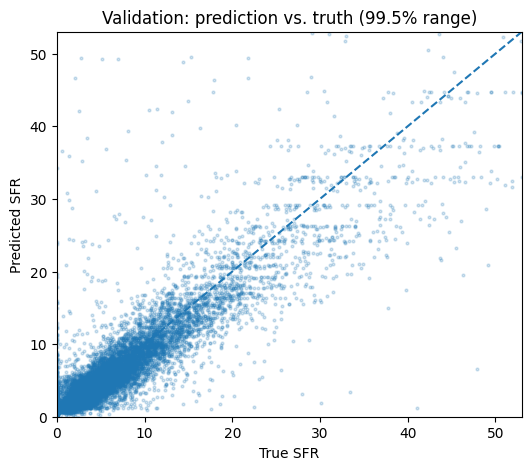

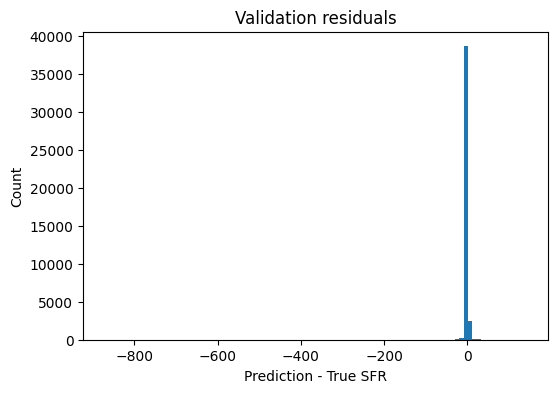

In [15]:
# Starter diagnostic plots — you may modify/add plots.
residual = np.asarray(VAL_PREDICTIONS) - y_val.to_numpy()

plt.figure(figsize=(6, 5))
plt.scatter(y_val, VAL_PREDICTIONS, s=4, alpha=0.2)
lims = [0, max(np.quantile(y_val, 0.995), np.quantile(VAL_PREDICTIONS, 0.995))]
plt.plot(lims, lims, "--")
plt.xlim(lims); plt.ylim(lims)
plt.xlabel("True SFR")
plt.ylabel("Predicted SFR")
plt.title("Validation: prediction vs. truth (99.5% range)")
plt.show()

plt.figure(figsize=(6, 4))
plt.hist(residual, bins=100)
plt.xlabel("Prediction - True SFR")
plt.ylabel("Count")
plt.title("Validation residuals")
plt.show()

### 11.1 Error-Analysis Discussion — **STUDENT RESPONSE**

**Zero / quiescent galaxies:** ...  
**Positive-SFR galaxies:** ...  
**High-SFR tail:** ...  
**Largest or most systematic failure mode:** ...  
**Likely explanation:** ...

## 12. Model Interpretation & Astrophysical Discussion — **REQUIRED**

Use an interpretation method appropriate for your model (for example, permutation importance, SHAP, ablation, partial dependence, learned graph/environmental analysis, or another justified method). The goal is not merely to rank features, but to connect the model behavior to the underlying astrophysics.

In [16]:
# STUDENT TODO — model interpretation.
# Example ideas: permutation importance, feature ablation, SHAP, partial dependence.
pass

### 12.1 Scientific Interpretation — **STUDENT RESPONSE**

Discuss:
- which information appears most important;
- whether the relationships are astrophysically plausible;
- what you learned about galaxy star formation or quenching;
- where interpretation is uncertain or model-dependent.

**Response:**  
...

## 13. Limitations & Conclusion — **REQUIRED**

### 13.1 Limitations
Identify at least **two substantive limitations** of your analysis, data, validation, or model.

1. ...
2. ...

### 13.2 Conclusion
In approximately **150–250 words**, state your final approach, main quantitative result, most important scientific/modeling insight, and what you would try next with more time or compute.

**Conclusion:**  
...

## 14. Final Model Card & Reproducibility — **REQUIRED**

Keep this concise and factual.

**Final model:** ...  
**Input features:** ...  
**Preprocessing / feature engineering:** ...  
**Target treatment:** ...  
**Validation strategy:** ...  
**Primary metric:** ...  
**Validation result:** ...  
**Random seed(s):** ...  
**Major hyperparameters:** ...  
**Approximate training time / hardware (if relevant):** ...  
**Biggest failure mode:** ...

## 15. Machine-Readable Results — **REQUIRED**

Keep the variable name `RESULTS`. This standardized block helps the instructors collect submission metadata and metrics consistently.

In [17]:
# STUDENT TODO — update model_name and notes; keep required keys.
_all = final_results.loc[final_results["Regime"] == "All"].iloc[0]
_zero = final_results.loc[final_results["Regime"] == "SFR = 0"].iloc[0]
_positive = final_results.loc[final_results["Regime"] == "SFR > 0"].iloc[0]

RESULTS = {
    "model_name": type(FINAL_MODEL).__name__,
    "features": list(FINAL_FEATURES),
    "n_features": len(FINAL_FEATURES),
    "random_seed": RANDOM_SEED,
    "validation_mae": float(_all["MAE"]),
    "validation_rmse": float(_all["RMSE"]),
    "validation_r2": float(_all["R2"]),
    "zero_sfr_mae": float(_zero["MAE"]),
    "positive_sfr_mae": float(_positive["MAE"]),
    "training_seconds": float(FINAL_TRAIN_SECONDS),
    "notes": "STUDENT TODO: one-line description of final approach",
}

print(json.dumps(RESULTS, indent=2))

{
  "model_name": "HistGradientBoostingRegressor",
  "features": [
    "log10_halo_mass",
    "log10_stellar_mass",
    "log10_BH_mass",
    "log10_main_prog_mass",
    "log10_main_prog_stellar_mass",
    "log10_mass_ratio",
    "log10_overdensity_plus_1",
    "pos_x",
    "pos_y",
    "pos_z",
    "vel_x",
    "vel_y",
    "vel_z"
  ],
  "n_features": 13,
  "random_seed": 42,
  "validation_mae": 1.2857589174133102,
  "validation_rmse": 9.525462617060612,
  "validation_r2": 0.3865729178594097,
  "zero_sfr_mae": 1.1759551108374309,
  "positive_sfr_mae": 1.2961689111561256,
  "training_seconds": 0.500532865524292,
  "notes": "STUDENT TODO: one-line description of final approach"
}


## 16. Final Submission Checklist

- [ ] Part I remains in the notebook and is complete.
- [ ] Changes since the midterm are documented.
- [ ] Final training and prediction code is included.
- [ ] Model comparison table is complete.
- [ ] Error analysis covers meaningful SFR regimes.
- [ ] Model interpretation is connected to astrophysics.
- [ ] Limitations and conclusion are complete.
- [ ] Final model card is complete.
- [ ] `RESULTS` executes successfully.
- [ ] All important figures have labels/captions and written interpretation.
- [ ] The notebook runs from top to bottom without hidden state or missing local variables.
- [ ] No unnecessary personal information is included.

**Submission reminder:** submit this completed notebook according to the official DataHub submission instructions.

**Required filename:** `DataHub_<ApplicationID>_mid/final.ipynb`

